# Stage 5 – CNN Embedding Graph Construction using Cosine Similarity

**Research:** An Unsupervised Graph-Based Framework for Adversarial Attack Detection and Severity Estimation in Deep Learning-Based Alzheimer’s MRI Classification.

## Purpose
Use the 128-dimensional CNN embeddings produced in Stage 4 to construct a sparse, weighted image-similarity graph. Each MRI image is a node; edges connect images with similar CNN representations. The graph will be used in Stage 6 (GCN) and Stage 7 (DGI).

## Alignment with the manuscript
The manuscript describes:
- 128-dimensional CNN feature representations.
- Graph construction based on cosine similarity.
- GCN and Deep Graph Infomax for graph representation learning.

The manuscript does not fully specify a numerical edge threshold or a k-nearest-neighbour value in the material available for this implementation. Therefore, this notebook uses **k = 10 nearest neighbours** as an explicit, provisional implementation choice. It must be reported as an implementation detail, not attributed to the manuscript. We will revisit it if the full manuscript specifies another graph rule.

## Graph protocol used here
- Node features: the 128-D CNN embeddings from Stage 4.
- Similarity: cosine similarity.
- Edge rule: connect each node to its 10 most similar other nodes.
- Symmetrisation: an undirected edge is retained if either endpoint selects the other (union symmetrisation).
- Edge weight: non-negative cosine similarity, clipped at zero.
- Self-loops: not added here; the GCN stage will add them explicitly if required by its layer formulation.
- Labels are not used to calculate similarities or choose edges.
- The saved train/validation/test masks preserve the Stage 3 split.

**Evaluation note:** This creates one transductive graph over all image embeddings. It uses no class labels to build edges, but validation/test image features participate in graph construction. This must be described accurately. If the intended manuscript protocol requires an inductive graph, we will instead construct training-only graph connectivity and attach validation/test nodes without using test labels.

## 1. Upload the Stage 4 output ZIP

Run this cell and upload `Stage4_CNN_Outputs.zip` from your computer.

In [1]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Uploaded: ['Stage4_CNN_Outputs.zip']


## 2. Imports and reproducibility

In [3]:
import os, glob, zipfile, json, random, shutil
import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3


## 3. Extract Stage 4 outputs

In [4]:
zip_files = [f for f in uploaded if f.lower().endswith(".zip")]
if not zip_files:
    raise FileNotFoundError("Please upload Stage4_CNN_Outputs.zip.")

STAGE4_ZIP = "/content/" + zip_files[0]
STAGE4_DIR = "/content/stage4_cnn_outputs"
os.makedirs(STAGE4_DIR, exist_ok=True)

with zipfile.ZipFile(STAGE4_ZIP, "r") as zf:
    zf.extractall(STAGE4_DIR)

for root, dirs, filenames in os.walk(STAGE4_DIR):
    for name in filenames:
        print(os.path.relpath(os.path.join(root, name), STAGE4_DIR))

cnn_embeddings_128d.npz
cnn_test_class_metrics.csv
cnn_embedding_manifest.csv
cnn_test_confusion_matrix.csv
cnn_training_history.csv
stage4_config_and_metrics.json
best_alzheimer_cnn.pth


## 4. Load embeddings and manifest

In [5]:
embedding_files = glob.glob(STAGE4_DIR + "/**/cnn_embeddings_128d.npz", recursive=True)
manifest_files = glob.glob(STAGE4_DIR + "/**/cnn_embedding_manifest.csv", recursive=True)
config_files = glob.glob(STAGE4_DIR + "/**/stage4_config_and_metrics.json", recursive=True)

if not embedding_files or not manifest_files:
    raise FileNotFoundError("Could not find CNN embeddings or embedding manifest in Stage 4 ZIP.")

with np.load(embedding_files[0], allow_pickle=False) as data:
    X_train = data["train_embeddings"].astype(np.float32)
    y_train = data["train_labels"].astype(np.int64)
    idx_train = data["train_indices"].astype(np.int64)

    X_val = data["validation_embeddings"].astype(np.float32)
    y_val = data["validation_labels"].astype(np.int64)
    idx_val = data["validation_indices"].astype(np.int64)

    X_test = data["test_embeddings"].astype(np.float32)
    y_test = data["test_labels"].astype(np.int64)
    idx_test = data["test_indices"].astype(np.int64)

manifest = pd.read_csv(manifest_files[0])
print("Train embeddings:", X_train.shape)
print("Validation embeddings:", X_val.shape)
print("Test embeddings:", X_test.shape)
print("Manifest:", manifest.shape)

assert X_train.shape == (4480, 128)
assert X_val.shape == (960, 128)
assert X_test.shape == (960, 128)
assert len(manifest) == 6400
assert "split" in manifest.columns and "label" in manifest.columns

Train embeddings: (4480, 128)
Validation embeddings: (960, 128)
Test embeddings: (960, 128)
Manifest: (6400, 5)


## 5. Reconstruct the original Stage 3 row order

In [6]:
# The embedding archive stores each split in split-specific order and records original Stage 3 indices.
all_embeddings = np.zeros((len(manifest), 128), dtype=np.float32)
all_embeddings[idx_train] = X_train
all_embeddings[idx_val] = X_val
all_embeddings[idx_test] = X_test

all_labels = np.zeros(len(manifest), dtype=np.int64)
all_labels[idx_train] = y_train
all_labels[idx_val] = y_val
all_labels[idx_test] = y_test

split_by_index = manifest["split"].to_numpy()
label_ids_manifest = manifest["label_id"].to_numpy(dtype=np.int64)

assert np.array_equal(all_labels, label_ids_manifest), "Embedding labels do not align with Stage 3 manifest."
assert np.isfinite(all_embeddings).all(), "Non-finite embedding values found."
assert np.linalg.norm(all_embeddings, axis=1).min() > 0, "At least one embedding has zero norm."

print("Reconstructed embedding matrix:", all_embeddings.shape)
print("Split counts:", pd.Series(split_by_index).value_counts().to_dict())

Reconstructed embedding matrix: (6400, 128)
Split counts: {'train': 4480, 'test': 960, 'validation': 960}


## 6. Configure cosine-similarity k-nearest-neighbour graph

In [7]:
# Provisional choice: manuscript says cosine similarity but does not specify k in the available details.
K_NEIGHBORS = 10

# Row-wise L2 normalisation makes dot products equal cosine similarities.
Z = normalize(all_embeddings, norm="l2", axis=1).astype(np.float32)

N = Z.shape[0]
if not (1 <= K_NEIGHBORS < N):
    raise ValueError("K_NEIGHBORS must be between 1 and number_of_nodes - 1.")

print("Number of nodes:", N)
print("Embedding dimension:", Z.shape[1])
print("k nearest neighbours:", K_NEIGHBORS)

Number of nodes: 6400
Embedding dimension: 128
k nearest neighbours: 10


## 7. Build the sparse cosine kNN graph

To avoid creating a dense 6,400 × 6,400 similarity matrix, similarities are computed in row batches. Each node selects its top-k other nodes. The graph is then symmetrised using the union rule.

In [8]:
from sklearn.neighbors import NearestNeighbors

# NearestNeighbors with cosine distance computes 1 - cosine similarity.
# Request k+1 because each node is its own nearest neighbour.
nn_model = NearestNeighbors(
    n_neighbors=K_NEIGHBORS + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
nn_model.fit(Z)
distances, neighbor_indices = nn_model.kneighbors(Z)

rows, cols, weights = [], [], []
for i in range(N):
    for dist, j in zip(distances[i], neighbor_indices[i]):
        if i == j:
            continue
        similarity = float(1.0 - dist)
        similarity = max(0.0, min(1.0, similarity))
        rows.append(i)
        cols.append(int(j))
        weights.append(similarity)

A_directed = sp.csr_matrix(
    (np.asarray(weights, dtype=np.float32), (rows, cols)),
    shape=(N, N),
    dtype=np.float32
)

# Union symmetrisation: retain an edge if either endpoint selected the other.
A = A_directed.maximum(A_directed.T).tocsr()
A.setdiag(0)
A.eliminate_zeros()

print("Directed kNN edges:", A_directed.nnz)
print("Undirected symmetric adjacency non-zero entries:", A.nnz)
print("Undirected edge count:", A.nnz // 2)
print("Graph density (excluding diagonal):", A.nnz / (N * (N - 1)))

Directed kNN edges: 64000
Undirected symmetric adjacency non-zero entries: 87362
Undirected edge count: 43681
Graph density (excluding diagonal): 0.0021331946397874666


## 8. Verify graph properties

In [9]:
# Check symmetry and absence of self-loops.
difference = A - A.T
max_asymmetry = 0.0 if difference.nnz == 0 else float(np.abs(difference.data).max())
diagonal_nonzeros = int(np.count_nonzero(A.diagonal()))

degrees = np.diff(A.indptr)
edge_weights = A.data

print("Maximum asymmetry:", max_asymmetry)
print("Self-loop count:", diagonal_nonzeros)
print("Minimum degree:", int(degrees.min()))
print("Median degree:", float(np.median(degrees)))
print("Maximum degree:", int(degrees.max()))
print("Mean degree:", float(degrees.mean()))
print("Edge weight min / mean / max:",
      float(edge_weights.min()), float(edge_weights.mean()), float(edge_weights.max()))

assert max_asymmetry < 1e-6
assert diagonal_nonzeros == 0
assert np.all(degrees > 0)
assert np.all(edge_weights >= 0)

Maximum asymmetry: 0.0
Self-loop count: 0
Minimum degree: 10
Median degree: 13.0
Maximum degree: 30
Mean degree: 13.6503125
Edge weight min / mean / max: 0.9257102012634277 0.9975016117095947 0.9999949336051941


## 9. Inspect degree and edge-weight distributions

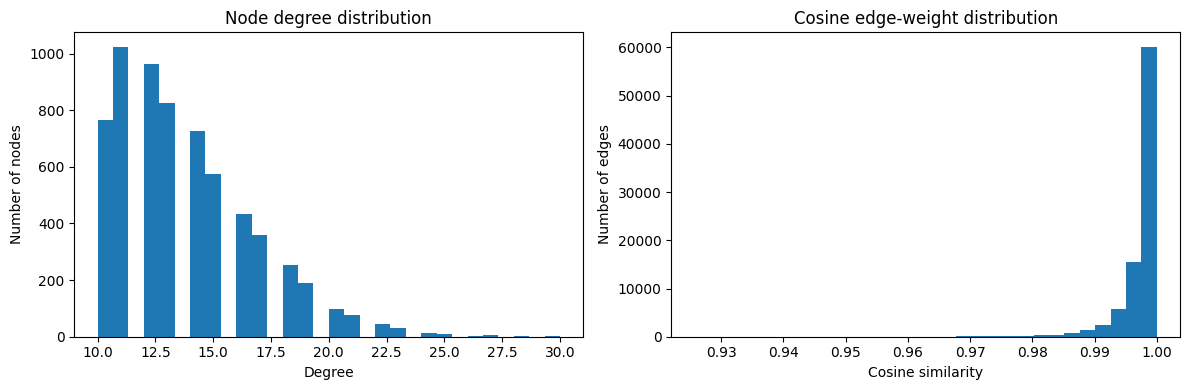

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(degrees, bins=30)
axes[0].set_title("Node degree distribution")
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Number of nodes")

axes[1].hist(edge_weights, bins=30)
axes[1].set_title("Cosine edge-weight distribution")
axes[1].set_xlabel("Cosine similarity")
axes[1].set_ylabel("Number of edges")
plt.tight_layout()
plt.show()

## 10. Create split masks and graph metadata

In [11]:
train_mask = (split_by_index == "train")
val_mask = (split_by_index == "validation")
test_mask = (split_by_index == "test")

assert train_mask.sum() == 4480
assert val_mask.sum() == 960
assert test_mask.sum() == 960
assert np.all(train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int) == 1)

# Count edges whose endpoints belong to different splits.
coo = A.tocoo()
upper = coo.row < coo.col
edge_u = coo.row[upper]
edge_v = coo.col[upper]
split_cross_edges = int(np.sum(split_by_index[edge_u] != split_by_index[edge_v]))
total_undirected_edges = len(edge_u)

print("Train nodes:", int(train_mask.sum()))
print("Validation nodes:", int(val_mask.sum()))
print("Test nodes:", int(test_mask.sum()))
print("Undirected edges:", total_undirected_edges)
print("Edges crossing split boundaries:", split_cross_edges)
print("Cross-split edge percentage:",
      100.0 * split_cross_edges / max(1, total_undirected_edges))

Train nodes: 4480
Validation nodes: 960
Test nodes: 960
Undirected edges: 43681
Edges crossing split boundaries: 19563
Cross-split edge percentage: 44.786062590142166


## 11. Save graph outputs

In [12]:
OUT_DIR = "/content/stage5_graph_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Sparse weighted adjacency matrix and edge list.
sp.save_npz(os.path.join(OUT_DIR, "cosine_knn_adjacency.npz"), A)

coo = A.tocoo()
edge_df = pd.DataFrame({
    "source_node": coo.row,
    "target_node": coo.col,
    "cosine_similarity": coo.data
})
edge_df.to_csv(os.path.join(OUT_DIR, "cosine_knn_edges_directed.csv"), index=False)

# Node table aligns every graph node to the Stage 3 manifest row.
node_df = manifest.copy()
node_df["node_id"] = np.arange(len(node_df))
node_df["label_id"] = all_labels
node_df.to_csv(os.path.join(OUT_DIR, "graph_node_manifest.csv"), index=False)

np.savez_compressed(
    os.path.join(OUT_DIR, "graph_node_features_and_masks.npz"),
    node_features=all_embeddings,
    labels=all_labels,
    train_mask=train_mask,
    validation_mask=val_mask,
    test_mask=test_mask
)

graph_config = {
    "node_count": int(N),
    "feature_dimension": int(Z.shape[1]),
    "similarity_metric": "cosine similarity",
    "edge_selection": "top-k nearest neighbours per node",
    "k_neighbors": int(K_NEIGHBORS),
    "symmetrization": "union (A = maximum(A_directed, A_directed.T))",
    "edge_weights": "non-negative cosine similarity, clipped to [0,1]",
    "self_loops_added": False,
    "graph_type": "weighted, undirected, sparse",
    "split_protocol": "transductive graph over all embeddings; split masks preserved; labels not used for edge construction",
    "random_seed": SEED,
    "directed_knn_edges": int(A_directed.nnz),
    "symmetric_adjacency_nonzeros": int(A.nnz),
    "undirected_edges": int(A.nnz // 2),
    "mean_degree": float(degrees.mean()),
    "minimum_degree": int(degrees.min()),
    "maximum_degree": int(degrees.max()),
    "cross_split_undirected_edges": split_cross_edges,
    "cross_split_edge_percentage": float(100.0 * split_cross_edges / max(1, total_undirected_edges)),
    "manuscript_alignment_note": "Cosine similarity graph is manuscript-aligned. k=10 and union symmetrisation are explicit implementation choices because a numerical edge rule was not specified in the available manuscript details."
}
with open(os.path.join(OUT_DIR, "graph_construction_config.json"), "w") as f:
    json.dump(graph_config, f, indent=2)

print("Output files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(filename, os.path.getsize(os.path.join(OUT_DIR, filename)), "bytes")

Output files:
cosine_knn_adjacency.npz 391726 bytes
cosine_knn_edges_directed.csv 1746036 bytes
graph_construction_config.json 1039 bytes
graph_node_features_and_masks.npz 1077301 bytes
graph_node_manifest.csv 833644 bytes


## 12. Download the Stage 5 graph package

In [13]:
from google.colab import files
shutil.make_archive("/content/Stage5_Graph_Outputs", "zip", OUT_DIR)
files.download("/content/Stage5_Graph_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What to send back

Upload `Stage5_Graph_Outputs.zip` here. I will verify:
- 6,400 nodes and 128 features per node.
- Sparse adjacency shape and symmetry.
- No self-loops at this stage.
- Degree and edge-weight distributions.
- Train/validation/test masks and cross-split edges.
- Graph construction configuration.

**Do not proceed to Stage 6 until the graph has been checked.**

### Research note
This notebook uses all 6,400 image embeddings to create one transductive graph. Although labels are not used to create edges, validation and test image features contribute to graph structure. We must keep this protocol consistent in later GCN/DGI evaluation and describe it transparently. If the manuscript requires an inductive evaluation protocol, we will adjust the graph construction before Stage 6 rather than silently mix protocols.